In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.special import erf 

In [ ]:
# data to gaussian
def dydx(x,y):
    dydx = []
    for i in range(1, len(x)-1):
        f = 0.5*((y[i+1]-y[i])/(x[i+1]-x[i]))+((y[i]-y[i-1])/(x[i]-x[i-1]))
        dydx.append(f)
    return dydx

def find_w(x,y):
    y8 = 0.08*y.max()
    y92 = 0.92*y.max()
    x_8 = x[np.argmin(np.abs(y - y8))]
    x_92 = x[np.argmin(np.abs(y - y92))] 
    w2 = x_92 - x_8
    return [w2,y8,y92,x_8,x_92]

# Gaussian function
def gaussian(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2))

def plot_gauss_width(x, y, popt, pcov=None, label='data', color='red', ax=None):
    A, mu, sigma = popt
    sigma = abs(sigma)
    dA, dmu, dsig = np.sqrt(np.diag(pcov)) if pcov is not None else (0, 0, 0)

    I0, Ie = A, A/np.e                 # peak and I0/e level
    w = np.sqrt(2)*sigma               # I(mu ± w) = I0/e
    two_w = 2*w
    d_two_w = 2*np.sqrt(2)*dsig        # error on 2w
    x1, x2 = mu - w, mu + w

    if pcov is not None:
        fit_eq = (f"f(x) = ({A:.3f} ± {dA:.3f}) exp[-(x - ({mu:.3f} ± {dmu:.3f}))² "
                  f"/ (2({sigma:.3f} ± {dsig:.3f})²)]")
    else:
        fit_eq = f"f(x) = {A:.3f} exp[-(x - {mu:.3f})² / (2·{sigma:.3f}²)]"

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))
    xf = np.linspace(min(x.min(), x1) - sigma, max(x.max(), x2) + sigma, 1000)
    ax.plot(x, y, 'o', mfc=color, mec='black', ms=5, label=label)
    ax.plot(xf, gaussian(xf, *popt), 'k-', label=f"fitted curve {label}: {fit_eq}")

    ax.axhline(I0, color='tab:blue',  ls='--', lw=1, label=f'$I_0$ = {I0:.3f}')
    ax.axhline(Ie, color='tab:green', ls='--', lw=1, label=f'$I_0/e$ = {Ie:.3f}')
    ax.vlines([x1, x2], 0, Ie, color='tab:red', ls=':', lw=1)
    ax.annotate('', xy=(x1, Ie), xytext=(x2, Ie),
                arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.5))
    ax.plot([], [], color='tab:red', label=f'$2w$ = {two_w:.3f} ± {d_two_w:.3f} mm')

    ax.set_ylim(0, 1.45*max(I0, np.max(y)))   # headroom so the legend doesn't hide points
    ax.set_xlabel('x (mm)')
    ax.set_ylabel(r'$\frac{dV}{dx}$ (V/mm)')
    ax.grid(); ax.legend(loc='upper right', fontsize=8)
    return dict(I0=I0, I0_over_e=Ie, w=w, two_w=two_w, d_two_w=d_two_w)

In [52]:
Total = [34.15, 34.125, 34.1, 34.085, 34.08, 34.07, 34.065, 34.06, 34.05, 34.045, 34.025, 34, 33.975, 33.95, 33.925, 33.875, 33.82, 33.775, 33.725, 
         33.675, 33.625, 33.55, 33.425, 33.25, 34.2, 34.225, 34.275]
Voltage = [12.55, 12.55, 11.89, 10.4, 9.4, 8.73, 8.1, 7.5, 6.89, 6.21, 5.04, 3.96, 2.89, 2.2, 1.69, 1.07, 0.77, 0.61, 0.49, 0.4, 0.34, 0.28, 0.2,
            0.14, 12.55, 12.55, 12.55]  # bf 


Total2= [34.275, 34.225, 34.175, 34.15, 34.125, 34.1, 34.075,34.06,34.05,34.025,34,33.975,
         33.95,33.925,33.9,33.875,33.85,33.825,33.8,33.775,33.75,33.7,33.645,33.575,
         33.5,33.45,33.4,33.3,33.225,33,32.875,32.75,32.675,32.5]
Voltage2 = [12.56, 12.56, 12.53, 10.34, 8.65, 7.24, 6.49    ,6.2,5.98,5.25,4.76,4.36,
            3.95,3.66,3.36,3.11,2.96,2.77,2.66,2.52,2.47,2.19,1.89,1.71,1.5,1.35,1.24,
            1.05,0.92,0.58,0.31,0.22,0.19,0.146] # af

Totalw=[33.5,33.475,33.45,33.4,33.375,33.365,33.355,33.345,33.335,33.325,33.3,33.275,33.25,33.225,33.2,33.175,33.15,33.125,33.075,33.025,32.975,32.925,32.875,32.825,32.75,32.7,32.65,32.575,32.5,32.25,32,31.5,31]
Voltagew=[12.56,12.56,12.56,12.56,10.87,9.87,9.1,8.48,7.835,7.12,6.235,5.457,4.66,4.128,3.568,3.01,2.75,2.52,2.08,1.8,1.63,1.4,1.19,1.06,0.91,0.83,0.75,0.73,0.69,0.54,0.45,0.3,0.21]
Totalw = [x + 0.755 for x in Totalw]


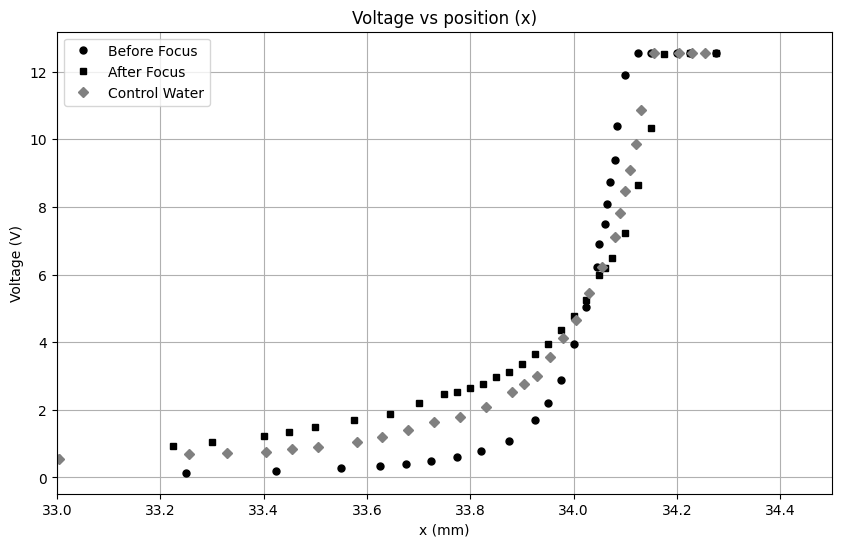

In [53]:

# ordering data
Total, Voltage = zip(*sorted(zip(Total, Voltage)))
Total2, Voltage2 = zip(*sorted(zip(Total2, Voltage2)))

plt.figure(figsize=(10, 6))
plt.plot(Total, Voltage,linestyle='',color='black', marker='o',label='Before Focus', markersize=5)
plt.plot(Total2, Voltage2,linestyle='',color='black', marker='s',label='After Focus', markersize=5)
plt.plot(Totalw, Voltagew,linestyle='',color='grey', marker='D',label='Control Water', markersize=5)
plt.title('Voltage vs position (x)')
plt.xlim(33, 34.5)
plt.xlabel('x (mm)') 
plt.ylabel('Voltage (V)')
plt.grid()
plt.legend()
plt.show()

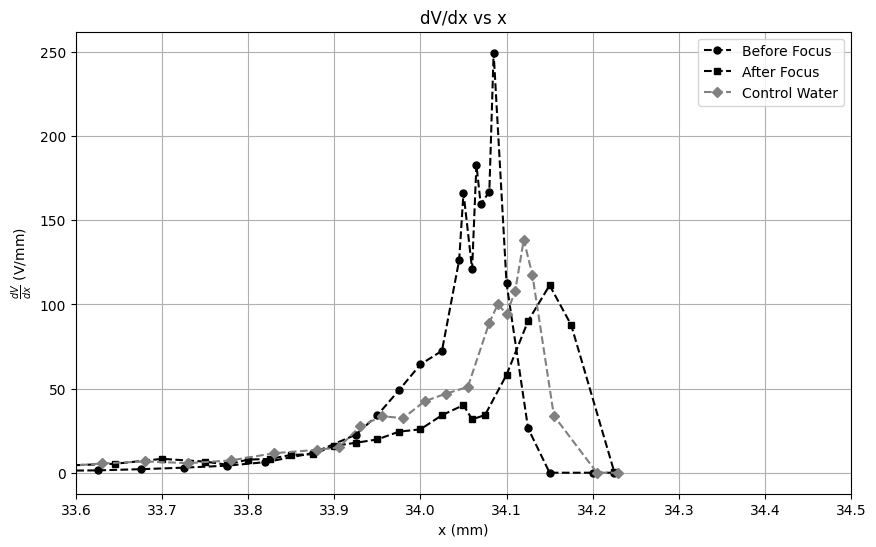

In [124]:

dV_bf = dydx(Total,Voltage)
T_bf = Total[1:-1]
dV_af = dydx(Total2,Voltage2)
T_af = Total2[1:-1]
dV_w = dydx(Totalw,Voltagew)
T_w = Totalw[1:-1]

plt.figure(figsize=(10, 6))
plt.plot(T_bf,dV_bf,linestyle='--',color='black', marker='o',label='Before Focus', markersize=5)
plt.plot(T_af,dV_af,linestyle='--',color='black', marker='s',label='After Focus', markersize=5)
plt.plot(T_w, dV_w,linestyle='--',color='grey', marker='D',label='Control Water', markersize=5)
plt.title('dV/dx vs x')
plt.xlim(33.6, 34.5)
plt.xlabel(r'x (mm)') 
plt.ylabel(r'$\frac{dV}{dx}$ (V/mm)')
plt.grid()
plt.legend()
plt.show()

In [55]:
# new data: 01

# x_af = [39.185 ,39.135 ,39.095 ,38.985 ,38.97 ,38.92 ,38.9 ,38.875 ,38.85 ,38.825 ,38.8 ,38.775 ,38.75 ,38.725 ,38.7 ,38.675 ,38.625 ,38.575 ,38.5 ,38.25 
#          ,38 ,37.75 ,37.5 ,37.25 ,37 ,36.75 ,36.5 ,36.25 ,36 ,35.75 ,35.5 ,35.25 ,35 ,34.75 ,34.5 ,34.25 ,34 ,33.75 ,33.5 ,33.25 ,33 ,32.75 ,32.5 ,32.25 ,32 ,31.75 ,31.5 ,31.25]

# V_af = [0.4168 ,0.4166 ,0.4165 ,0.416 ,0.4156 ,0.4151 ,0.415 ,0.4148 ,0.4145 ,0.4144 ,0.4141 ,0.4139 ,0.4138 ,0.4137 ,0.4134 ,0.4131 ,0.4129 ,0.4124 ,0.412 ,
#            0.4099 ,0.4071 ,0.4042 ,0.4012 ,0.3982 ,0.3948 ,0.3906 ,0.3859 ,0.3795 ,0.3715 ,0.3617 ,0.3492 ,0.3338 ,0.3106 ,0.2617 ,0.202 ,0.1667 ,0.1537 ,0.1366 ,0.1324 ,0.1317 
#            ,0.1272 ,0.1257 ,0.1248 ,0.1242 ,0.1238 ,0.1235 ,0.123 ,0.1198]

# x_bf = [38.595 ,38.5 ,38.475 ,38.04 ,38 ,37.975 ,38.45 ,38.425 ,38.4 ,38.375 ,38.325 ,38.25 ,38.225 ,38.1 ,38.075 ,38.05 ,38.02 ,38 ,37.975 ,37.95 ,37.925 ,37.9 ,37.875 ,37.85 
#         ,37.825 ,37.8 ,37.775 ,37.75 ,37.7 ,37.65 ,37.6 ,37.55 ,37.5 ,37.45 ,37.4 ,37.35 ,37.3 ,37.25 ,37 ,36.75 ,36.5 ,36.25 ,
#         35.75 ,35.5 ,35.25 ,35 ,34.75 ,34.5 ,34.25,34 ,33.75 ,33.5 ,33.25 ,33 ,32.5]

# V_bf = [0.426 ,0.426 ,0.4267 ,0.4264 ,0.4264 ,0.4264 ,0.4264 ,0.4264 ,0.4265 ,0.4265 ,0.4262 ,0.426 ,0.4259 ,0.4258 ,0.4256 ,0.4259 ,0.4256 ,0.4252 ,0.425 ,0.4247 ,0.4246 
#         ,0.4243 ,0.424 ,0.4236 ,0.4232 ,0.4229 ,0.4225 ,0.4218 ,0.4207 ,0.4197 ,0.4184 ,0.4171 ,0.4153 ,0.4137 ,0.4112 ,0.4094 ,0.407 ,0.4049 ,0.3902 ,0.3739 ,0.3583 ,0.3545 
#          ,0.3477 ,0.3301 ,0.3079 ,0.2769 ,0.2242 ,0.1599 ,0.1427 ,0.1348 ,0.1337 ,0.1318 ,0.1315 ,0.1312 ,0.1299]

# new data: 02

# x_afn = [40.5,40.25,40,39.75,39.5,39.25,39,38.75,38.5,38.25,38,37.75,37.5,37.25,37,36.75,36.5,36.25,36,35.75,35.625,35.5,35.37,35.25,35,34.75,34.5,34.25,
#          34.125,34,33.875,33.75,33.625,33.5,33.25,33,32.75,32.5,32]

# V_afn = [0.4035 ,0.4033 ,0.4028 ,0.4016 ,0.3999 ,0.398 ,0.3952 ,0.3923 ,0.3895 ,0.3864 ,0.3833 ,0.3792 ,0.3746 ,0.3692 ,0.3619 ,0.3542 ,0.3438 ,0.3302 ,0.3114 ,0.2698 ,0.2327 
#         ,0.204 ,0.1793 ,0.1595 ,0.1261 ,0.0771 ,0.0656 ,0.0474 ,0.0356 ,0.03 ,0.0232 ,0.0209 ,0.0179 ,0.0168 ,0.0145 ,0.0133 ,0.0122 ,0.0108 ,0.01]


x_bfn = [40 ,39.75 ,39.5 ,39.25 ,39 ,38.75 ,38.5 ,38.25 ,38 ,37.75 ,37.5 ,37.25 ,37.125 ,37 ,36.875 ,36.75 ,36.625 ,36.5 ,36.375 ,36.25 ,36.125 ,36 ,35.875 ,35.75 ,35.61 ,35.5 ,
        35.375 ,35.25 ,35.125 ,35 ,34.875 ,34.75 ,34.625 ,34.5 ,34.375 ,34.25 ,34.1 ,34 ,33.75 ,33.5 ,33.25 ,33 ,32.745 ,32.5]
V_bfn = [0.4126 ,0.4125 ,0.4126 ,0.4154 ,0.4155 ,0.4153 ,0.4154 ,0.4154 ,0.4152 ,0.4149 ,0.4142 ,0.4132 ,0.4109 ,0.4075 ,0.4014 ,0.395 ,0.3857 ,0.3765 ,0.3644 ,0.3533 ,0.3404 
        ,0.3306 ,0.3214 ,0.3139 ,0.3039 ,0.2949 ,0.2798 ,0.2652 ,0.2453 ,0.2265 ,0.2075 ,0.1812 ,0.1391 ,0.093 ,0.051 ,0.034 ,0.027 ,0.022 ,0.021 ,0.018 ,0.016 ,0.015 ,0.014 ,
        0.0133]

x_afn = [31 ,31.25 ,31.5 ,31.75 ,32 ,32.25 ,32.5 ,32.75 ,33 ,33.25 ,33.5 ,33.75 ,34 ,34.25 ,34.5 ,34.75 ,35 ,35.25 ,35.5 ,35.75 ,36 ,36.25 ,36.5 ,36.75 ,
         37 ,37.25 ,37.5 ,37.75 ,38 ,38.25 ,38.5 ,38.75 ,39 ,39.25]
V_afn = [0.0076 ,0.009 ,0.0087 ,0.0098 ,0.0109 ,0.0124 ,0.0131 ,0.0153 ,0.0185 ,0.0245 ,0.045 ,0.074 ,0.1253 ,0.1571 ,0.1982 ,0.2628 ,0.3088 ,0.3293 ,
         0.3436 ,0.3546 ,0.3639 ,0.3713 ,0.377 ,0.3825 ,0.387 ,0.3908 ,0.3943 ,0.3974 ,0.4001 ,0.4026 ,0.4046 ,0.4065 ,0.4078 ,0.4088]


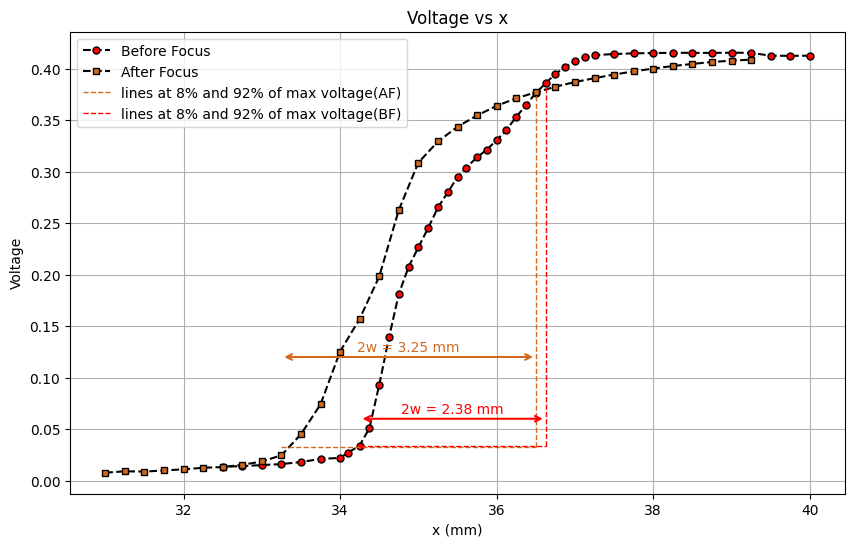

In [118]:
# x_af_ = np.asarray(x_af, dtype=float)
# V_af_ = np.asarray(V_af, dtype=float)
# x_bf_ = np.asarray(x_bf, dtype=float)
# V_bf_ = np.asarray(V_bf, dtype=float)

x_af_n = np.asarray(x_afn, dtype=float)
V_af_n = np.asarray(V_afn, dtype=float)
x_bf_n = np.asarray(x_bfn, dtype=float)
V_bf_n = np.asarray(V_bfn, dtype=float)

w_af = find_w(x_af_n,V_af_n)
w_bf = find_w(x_bf_n,V_bf_n)

#plot
plt.figure(figsize=(10, 6))
plt.plot(x_bf_n,V_bf_n,linestyle='--',color='black',markerfacecolor = 'red', marker='o',label='Before Focus', markersize=5)
plt.plot(x_af_n,V_af_n,linestyle='--',color='black', markerfacecolor = 'chocolate',marker='s',label='After Focus', markersize=5)
plt.vlines(x=w_af[4], ymin=w_af[1],ymax=w_af[2],color='chocolate',  ls='--', lw=1, label='lines at 8% and 92% of max voltage(AF)')
plt.hlines(w_af[1], xmin=w_af[3],xmax=w_af[4],color='chocolate',  ls='--', lw=1)
plt.vlines(x=w_bf[4], ymin=w_bf[1],ymax=w_bf[2],color='red',  ls='--', lw=1, label='lines at 8% and 92% of max voltage(BF)')
plt.hlines(w_bf[1], xmin=w_bf[3],xmax=w_bf[4],color='red',  ls='--', lw=1)
plt.annotate('', xy=(w_af[3], 0.12), xytext=(w_af[4], 0.12), arrowprops=dict(arrowstyle='<->', color='chocolate', lw=1.5))
plt.text((w_af[3]+w_af[4])/2, 0.125, f'2w = {w_af[0]:.2f} mm', color='chocolate', ha='center')
plt.annotate('', xy=(w_bf[3], 0.06), xytext=(w_bf[4], 0.06), arrowprops=dict(arrowstyle='<->', color='red', lw=1.5))
plt.text((w_bf[3]+w_bf[4])/2, 0.065, f'2w = {w_bf[0]:.2f} mm', color='red', ha='center')
plt.title(r'Voltage vs x')
plt.xlabel(r'x (mm)')
plt.ylabel('Voltage')
plt.legend()
plt.grid()
plt.show()


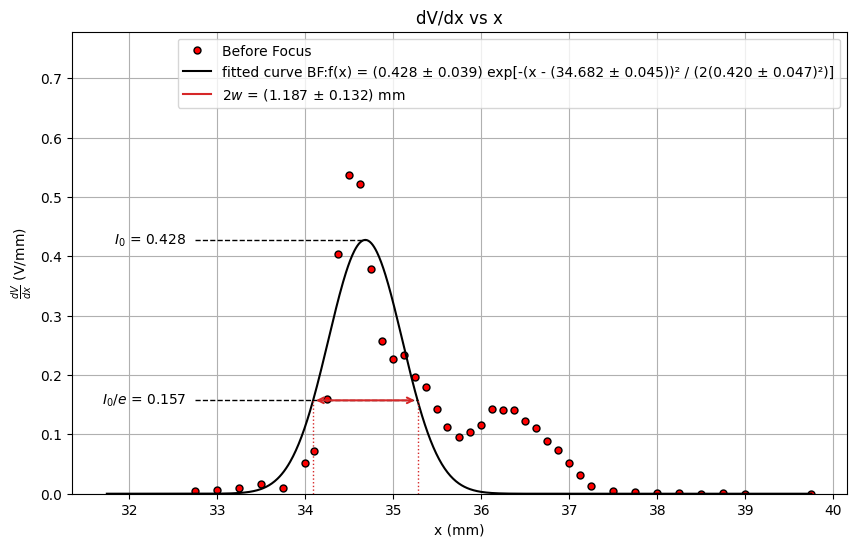

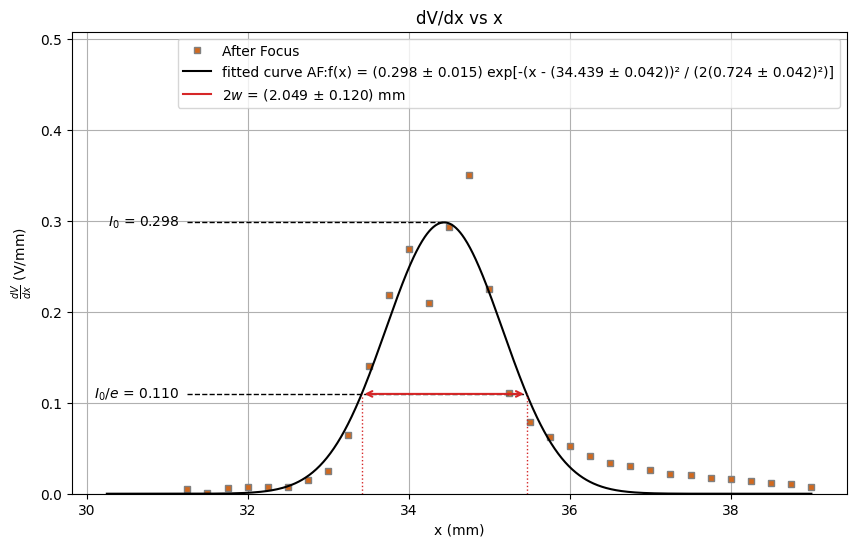

In [106]:
# gaussian

y_afg = dydx(x_af_n,V_af_n)
x_afg = x_af_n[1:-1]
y_bfg = dydx(x_bf_n,V_bf_n)
x_bfg = x_bf_n[1:-1]

# fitting gaussian
initial_guess = [max(y_afg), x_afg[np.argmax(y_afg)], 1.0]
popt, pcov = curve_fit( gaussian, x_afg, y_afg, p0=initial_guess)

initial_guess1 = [max(y_bfg), x_bfg[np.argmax(y_bfg)], 1.0]
popt1, pcov1 = curve_fit( gaussian, x_bfg, y_bfg, p0=initial_guess1)
x_fit1 = np.linspace(x_bfg.min()-1,x_bfg.max(),1000)
x_fit = np.linspace(x_afg.min()-1,x_afg.max(),1000)

A, mu, sigma = popt
dA, dmu, dsigma = np.sqrt(np.diag(pcov))
A1, mu1, sigma1 = popt1
dA1, dmu1, dsigma1 = np.sqrt(np.diag(pcov1))
fit_eq = f"f(x) = ({A:.3f} ± {dA:.3f}) exp[-(x - ({mu:.3f} ± {dmu:.3f}))² / (2({sigma:.3f} ± {dsigma:.3f})²)]"
fit_eq1 = f"f(x) = ({A1:.3f} ± {dA1:.3f}) exp[-(x - ({mu1:.3f} ± {dmu1:.3f}))² / (2({sigma1:.3f} ± {dsigma1:.3f})²)]"
w1 = np.sqrt(2)*sigma1              # I(mu ± w) = I0/e
two_w1 = 2*w1
d_two_w1 = 2*np.sqrt(2)*dsigma1        # error on 2w
x1_1, x2_1 = mu1 - w1, mu1 + w1
w = np.sqrt(2)*sigma       # I(mu ± w) = I0/e
two_w = 2*w
d_two_w = 2*np.sqrt(2)*dsigma       # error on 2w
x1, x2 = mu - w, mu + w


plt.figure(figsize=(10, 6))
plt.plot(x_bfg,y_bfg,linestyle='',color='black',markerfacecolor = 'red', marker='o',label='Before Focus', markersize=5)
plt.plot(x_fit1,gaussian(x_fit1,*popt1),color= "black", label=f"fitted curve BF:{fit_eq1}")
plt.hlines(A1, xmin=x_bfg.min(),xmax=mu1,color='black',  ls='--', lw=1)
plt.annotate('', xy=(x1_1, A1/np.e), xytext=(x2_1, A1/np.e),arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.5))
plt.text(x= x_bfg.min()-0.1,y=A1,s=f'$I_0$ = {A1:.3f}',color='black',va='center',ha='right')
plt.hlines(A1/np.e, xmin=x_bfg.min(),xmax=x2_1, color='black', ls='--', lw=1)
plt.text(x= x_bfg.min()-0.1,y=A1/np.e,s=f'$I_0/e$ = {A1/np.e:.3f}',color='black',va='center',ha='right')
plt.plot([], [], color='tab:red', label=f'$2w$ = ({two_w1:.3f} ± {d_two_w1:.3f}) mm')
plt.ylim(0, 1.45*max(A1, np.max(y_bfg)))
plt.vlines([x1_1, x2_1], 0, A1/np.e, color='tab:red', ls=':', lw=1)
plt.title('dV/dx vs x')
plt.xlabel(r'x (mm)') 
plt.ylabel(r'$\frac{dV}{dx}$ (V/mm)')
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_afg,y_afg,linestyle='',color='grey',markerfacecolor = 'chocolate', marker='s',label='After Focus', markersize=5)
plt.plot(x_fit,gaussian(x_fit,*popt),color= "black", label=f"fitted curve AF:{fit_eq}")
plt.hlines(A, xmin=x_afg.min(),xmax=mu,color='black',  ls='--', lw=1)
plt.annotate('', xy=(x1, A/np.e), xytext=(x2, A/np.e),arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.5))
plt.text(x= x_afg.min()-0.1,y=A,s=f'$I_0$ = {A:.3f}',color='black',va='center',ha='right')
plt.hlines(A/np.e, xmin=x_afg.min(),xmax=x2, color='black', ls='--', lw=1)
plt.text(x= x_afg.min()-0.1,y=A/np.e,s=f'$ I_0/e$ = {A/np.e:.3f}',color='black',va='center',ha='right')
plt.plot([], [], color='tab:red', label=f'$2w$ = ({two_w:.3f} ± {d_two_w:.3f}) mm')
plt.ylim(0, 1.45*max(A, np.max(y_afg)))
plt.vlines([x1, x2], 0, A/np.e, color='tab:red', ls=':', lw=1)
plt.title('dV/dx vs x')
plt.xlabel(r'x (mm)') 
plt.ylabel(r'$\frac{dV}{dx}$ (V/mm)')
plt.grid()
plt.legend()
plt.show()

